## Visualizing exchanges within community

This script corresponds to the modeling of an MCF-7 community in co-culture with Fusobacterium nucleatum. In this part, the objetive was visualizing the exchanges within community.

#### Import packages and CSV file with fluxes

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
fluxesTyF = pd.read_csv('TyF.csv', index_col=0) #load the ouput file that included all fluxes

In [3]:
fluxesTyF

,10FTHF5GLUtl,10FTHF5GLUtm,10FTHF6GLUtl,10FTHF6GLUtm,10FTHF7GLUtl,10FTHF7GLUtm,10FTHFtl,10FTHFtm,15DAPt,1PPDCRp,...,r2503,r2513,r2521,r2537,r2539,rtranscription,sink_citr_LPAREN_c_RPAREN_,sink_dmbzid,sink_s,xmpt
compartment,,,,,,,,,,,,,,,,,,,,,
CanA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,NaN,-0.0,0.0,-0.0,NaN,NaN,NaN,NaN,NaN,0.000515
CanB,-0.0,-0.0,NaN,NaN,NaN,NaN,0.0,0.0,NaN,NaN,...,NaN,-0.0,NaN,-0.0,NaN,NaN,NaN,NaN,NaN,0.000000
CanC,-0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,NaN,-0.0,...,0.0,-0.0,NaN,-0.0,-0.0,NaN,0.029998,NaN,NaN,-0.000111
Fusobacterium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,0.114456,NaN,0.0,0.0,NaN
medium,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Exchange reactions**

In [3]:
exchange_cols = fluxesTyF.columns[fluxesTyF.columns.str.startswith("EX_")] #Extract exchange fluxes

In [4]:
community_exchanges = fluxesTyF[exchange_cols]
community_exchanges_vertical = community_exchanges.reset_index().melt(
    id_vars="compartment", var_name="reaction", value_name="flux"
)
community_exchanges_nz = community_exchanges_vertical[
    community_exchanges_vertical["flux"] != 0
]
community_exchanges_vertical["type"] = community_exchanges_vertical["flux"].apply(
    lambda x: "consumed" if x < 0 else ("secreted" if x > 0 else "no flux")
)

In [5]:
community_exchanges_nz

,compartment,reaction,flux
0,CanA,EX_15dap_e,NaN
1,CanB,EX_15dap_e,NaN
2,CanC,EX_15dap_e,NaN
4,medium,EX_15dap_e,NaN
5,CanA,EX_15dap_m,NaN
...,...,...,...
2455,CanA,EX_zn2_m,NaN
2456,CanB,EX_zn2_m,NaN
2457,CanC,EX_zn2_m,NaN
2458,Fusobacterium,EX_zn2_m,NaN


#### Visualizing

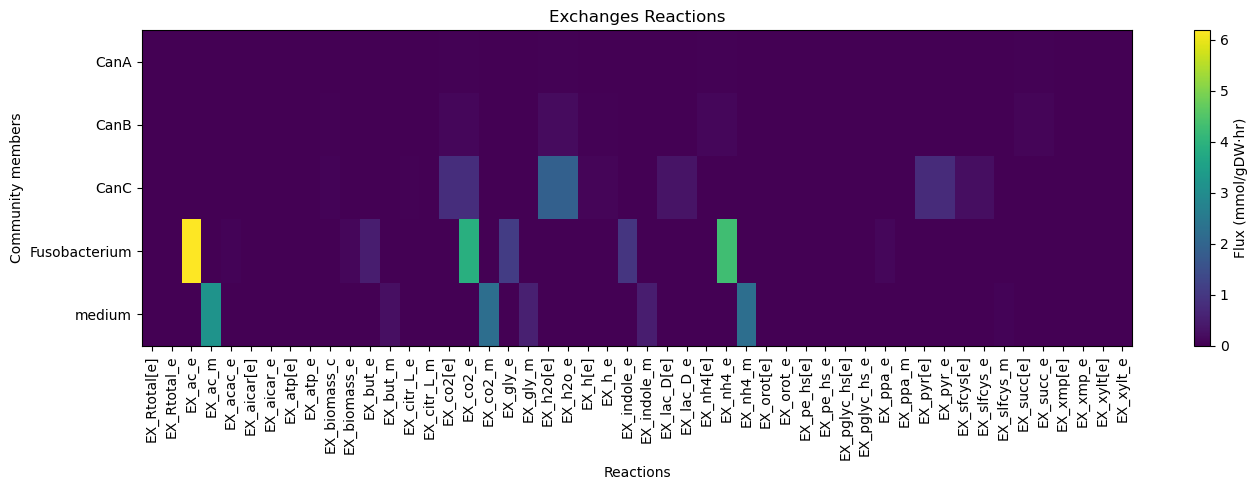

In [21]:
# Copy of original dataframe 
df = community_exchanges_nz.copy()

# Only secreted metabolites (flux > 0)
df_secreted = df[df["flux"] > 0].copy()

# heatmap
pivot = df_secreted.pivot_table(
    index="compartment",       # rows = species / taxon
    columns="reaction",   # columns = metabolites
    values="flux",        # value = secreted flux
    fill_value=0
)

# 
plt.figure(figsize=(14, 5))

#
plt.imshow(pivot, aspect="auto")

# Tags
plt.xticks(ticks=np.arange(len(pivot.columns)), labels=pivot.columns, rotation=90)
plt.yticks(ticks=np.arange(len(pivot.index)), labels=pivot.index)

plt.colorbar(label="Flux (mmol/gDW·hr)")
plt.title("Exchanges Reactions")
plt.xlabel("Reactions")
plt.ylabel("Community members")

plt.tight_layout()
plt.savefig("plots/reacciones_intercambio.png", dpi=300, bbox_inches="tight")
plt.show()

## **Exchange reactions within community: Exchanges dynamics**

In [7]:
ex_fluxes = fluxesTyF.loc[:, fluxesTyF.columns.str.startswith("EX_")]
ex_fluxes = ex_fluxes.copy()
ex_fluxes["compartment"] = ex_fluxes.index

# 
ex_long = ex_fluxes.melt(
    id_vars="compartment",
    var_name="reaction",
    value_name="flux"
)

#Filter non-zero fluxes
ex_long = ex_long[ex_long["flux"] != 0] 

# Consumed vs Secreted id 
ex_long["type"] = ex_long["flux"].apply(lambda x: "secreted" if x > 0 else "consumed")

# Name of metabolite 
ex_long["metabolite"] = (
    ex_long["reaction"]
    .str.replace("EX_", "", regex=False)
    .str.replace("_e", "", regex=False)
    .str.replace("[e]", "", regex=False)
)
# Identify exchange metabolites
secreted = ex_long[ex_long["type"] == "secreted"]
consumed = ex_long[ex_long["type"] == "consumed"]

exchanged = pd.merge(
    secreted,
    consumed,
    on="metabolite",
    suffixes=("_producer", "_consumer")
)

# Results
exchanged = exchanged[[
    "metabolite",
    "compartment_producer",
    "flux_producer",
    "compartment_consumer",
    "flux_consumer"
]].sort_values("metabolite")
print(exchanged)


    metabolite compartment_producer  flux_producer compartment_consumer  \
0       Rtotal                 CanC       0.017429                 CanA   
15      Rtotal                 CanC       0.017429               medium   
14      Rtotal                 CanC       0.017429        Fusobacterium   
13      Rtotal                 CanC       0.017429                 CanB   
11      Rtotal                 CanC       0.017429               medium   
..         ...                  ...            ...                  ...   
325       xylt                 CanC       0.007768                 CanB   
324       xylt                 CanC       0.007768                 CanA   
338       xylt                 CanC       0.007768        Fusobacterium   
330       xylt                 CanC       0.007768        Fusobacterium   
339       xylt                 CanC       0.007768               medium   

     flux_consumer  
0        -0.004606  
15             NaN  
14             NaN  
13       -0.019

In [9]:
exchanged.to_csv("exchanges_complete.csv") #this dataframe include all the exchanges reactions.

### Vizualizing

In [2]:
exchanges_complete = pd.read_csv('exchanges_complete_modificate.csv', index_col=0) #this dataframe exclude reactions like h2o, h, biomass, co2

In [3]:
exchanges_complete

,compartment_producer,flux_producer,compartment_consumer,flux_consumer
metabolite,,,,
ac,Fusobacterium,6.188380,Fusobacterium,NaN
ac,Fusobacterium,6.188380,medium,NaN
ac,Fusobacterium,6.188380,medium,NaN
ac_m,medium,3.187094,CanA,NaN
ac_m,medium,3.187094,CanB,NaN
...,...,...,...,...
xylt,CanC,0.007768,CanB,-0.007865
xylt,CanC,0.007768,CanA,-0.004543
xylt,CanC,0.007768,Fusobacterium,NaN


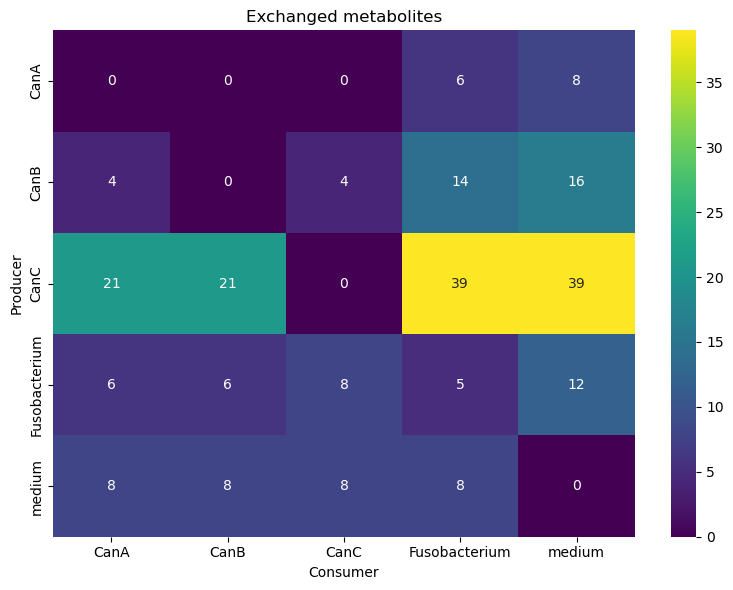

In [4]:
# Make a matrix specie-producer vs specie-consumer 
#without h20, h, biomass,  Rtotal
matrix = exchanges_complete.groupby(
    ["compartment_producer", "compartment_consumer"]
).size().unstack(fill_value=0)

plt.figure(figsize=(8,6))
sns.heatmap(matrix, annot=True, fmt="d", cmap="viridis")
plt.title("Exchanged metabolites")
plt.xlabel("Consumer")
plt.ylabel("Producer")
plt.tight_layout()
plt.savefig("plots/intercambio_metabolitos_new.png", dpi=300, bbox_inches="tight")
plt.show()

#### **Add magnitude**

In [5]:
exchanges_complete["magnitude"] = exchanges_complete[["flux_producer", "flux_consumer"]].abs().max(axis=1)

In [6]:
exchanges_complete.sort_values("magnitude", ascending=False) 

,compartment_producer,flux_producer,compartment_consumer,flux_consumer,magnitude
metabolite,,,,,
ac,Fusobacterium,6.188380,Fusobacterium,NaN,6.188380
ac,Fusobacterium,6.188380,medium,NaN,6.188380
ac,Fusobacterium,6.188380,medium,NaN,6.188380
nh4,Fusobacterium,4.295426,medium,NaN,4.295426
nh4,Fusobacterium,4.295426,Fusobacterium,NaN,4.295426
...,...,...,...,...,...
xmp,CanC,0.000111,Fusobacterium,NaN,0.000111
xmp,CanC,0.000111,medium,NaN,0.000111
xmp,CanC,0.000111,medium,NaN,0.000111


#### **Change magnitude to percentage**

In [7]:
exchanges_complete["percentage"] = (
    exchanges_complete["magnitude"] /
    exchanges_complete.groupby("compartment_producer")["magnitude"].transform("sum")
) * 100

In [8]:
exchanges_complete

,compartment_producer,flux_producer,compartment_consumer,flux_consumer,magnitude,percentage
metabolite,,,,,,
ac,Fusobacterium,6.188380,Fusobacterium,NaN,6.188380,12.749247
ac,Fusobacterium,6.188380,medium,NaN,6.188380,12.749247
ac,Fusobacterium,6.188380,medium,NaN,6.188380,12.749247
ac_m,medium,3.187094,CanA,NaN,3.187094,11.710890
ac_m,medium,3.187094,CanB,NaN,3.187094,11.710890
...,...,...,...,...,...,...
xylt,CanC,0.007768,CanB,-0.007865,0.007865,0.076349
xylt,CanC,0.007768,CanA,-0.004543,0.007768,0.075410
xylt,CanC,0.007768,Fusobacterium,NaN,0.007768,0.075410


In [10]:
exchanges_complete.groupby("metabolite")["percentage"].sum().sort_values(ascending=False) #see the percentage distribution

metabolite
pyr         99.157467
nh4         96.024138
succ        92.569602
ac_m        46.843559
ac          38.247742
nh4_m       32.830799
lac_D       24.992015
gly         20.332562
gly_m        8.165565
indole       7.943909
indole_m     7.296920
sfcys        4.692443
slfcys       4.692443
but          4.025572
but_m        3.697711
ppa          2.086690
xylt         1.210317
citr_L       1.164818
slfcys_m     0.828777
acac         0.815327
orot         0.749683
aicar        0.554621
pe_hs        0.362845
atp          0.254230
ppa_m        0.233804
citr_L_m     0.102865
pglyc_hs     0.094982
xmp          0.028596
Name: percentage, dtype: float64

In [11]:
exchanges_complete.to_csv("EXCHANGES_FILES/exchanges_complete.csv") #save the dataframe for vizualizing in ggplot2

In [13]:
exchanges_complete[exchanges_complete["percentage"] > 2] # Only percentage > 2

,compartment_producer,flux_producer,compartment_consumer,flux_consumer,magnitude,percentage
metabolite,,,,,,
ac,Fusobacterium,6.188380,Fusobacterium,NaN,6.188380,12.749247
ac,Fusobacterium,6.188380,medium,NaN,6.188380,12.749247
ac,Fusobacterium,6.188380,medium,NaN,6.188380,12.749247
ac_m,medium,3.187094,CanA,NaN,3.187094,11.710890
ac_m,medium,3.187094,CanB,NaN,3.187094,11.710890
...,...,...,...,...,...,...
succ,CanB,0.080236,Fusobacterium,NaN,0.080236,3.897464
succ,CanA,0.024566,medium,NaN,0.024566,6.454836
succ,CanA,0.024566,Fusobacterium,-0.040094,0.040094,10.534853
